In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [3]:
# load data into df

df = pd.read_csv("../data/processed/pharma_sales_data_string_cleaned.csv", encoding="utf-8", na_values=["", "NA", "-", "?"])

# Univariate Analysis

<h3> Numeric Column </h3>

In [11]:
# numeric columnss

numeric_columns = [c for c in df.columns if(df[c].dtype == "float64")]
numeric_columns

['m01ab', 'm01ae', 'n02ba', 'n02be', 'n05b', 'n05c', 'r03', 'r06']

c:\Users\shank\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\shank\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\shank\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\shank\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

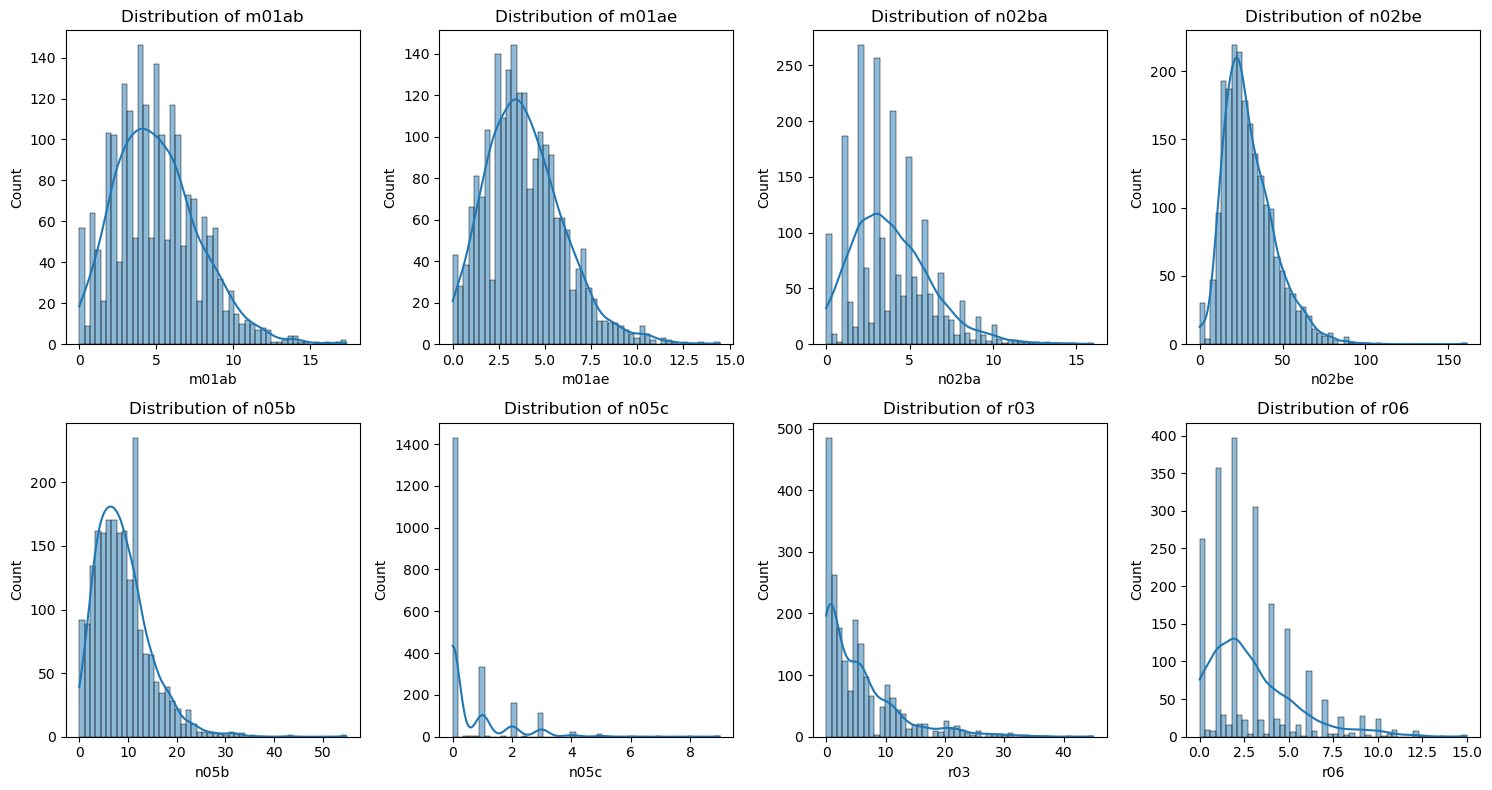

In [ ]:

# create 2x4 subplot's grid 

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(15,8))

# Flatten the axes array for easy iteration

axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    sns.histplot(df, x=col, bins=50, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

# Adjust layout and show
plt.tight_layout()
plt.show()

In [43]:
# get the skew values and show only strongly skewed columns (> 1) -> solution = log/box-cox

skew_data = df[numeric_columns].skew().sort_values().reset_index()
skew_data = skew_data[skew_data[0]>1]
skew_data = skew_data.rename(columns={'index':'drug type', 0: 'skew'})
skew_data

,drug type,skew
3,n02be,1.202291
4,r06,1.292813
5,n05b,1.324840
6,r03,1.829746
7,n05c,2.520468


In [ ]:
# check for spikes to reveal sentinels, defaults or two-part process

df[numeric_columns].value_counts().head()

(df[numeric_columns]==0).mean()

# no specific sentinal values

m01ab    0.018993
m01ae    0.017094
n02ba    0.037037
n02be    0.012346
n05b     0.020418
n05c     0.679012
r03      0.229820
r06      0.121557
dtype: float64

<h3> Categorical Column </h3>

<Axes: ylabel='weekday_name'>

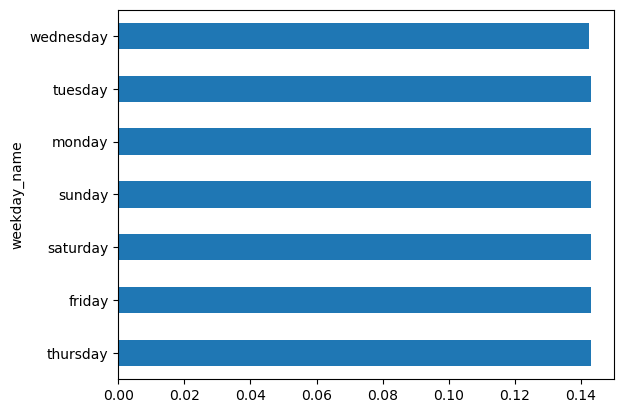

In [46]:
# frequency table for weekday column
df["weekday_name"].value_counts(normalize=True, dropna=False).plot.barh()